![](images/graph_basics.png)

### 🕸️ Agents as graphs (the LangGraph way)

LangGraph was inspired by other graph-based tools to apply a graph-first mode of thinking to agents.

Graph **nodes** and **edges** allow agent developers to map out the exact components and actions to build more complex workflows involving LLMs.

To get started, you'll build a graph state, which will save user and assistant messages in a conversation history, so conversations can progress.

To do this, we first create a `State` class:

```py
class State(TypedDict):
    messages: Annotated[list, add_messages]
```

All this means is that the `State` class has some messages (`messages`), and these messages are a list where new messages are appended to it rather than overridden (indicated with the `add_messages()` function).

This `State` class is then converted into a graph state object using `StateGraph`.

**Run this cell to set up your environment**

In [41]:
!pip install --quiet langgraph==0.5.3 langchain-openai==0.3.16 pydantic==2.11.9


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


**Complete the code to create a `State` class and convert it into a graph state.**

In [42]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

# Create the state to capture the messages
class State(TypedDict):
    messages: Annotated[list, add_messages]

# Create the graph state
graph_builder = StateGraph(State)

This graph state is often assigned to `graph_builder` or `workflow`, as this object represents the instructions to create the graph rather than the graph itself. This is analogous to a recipe and the final meal.

![](images/llm_as_a_graph.png)

With the graph state up and running, it's time to define your first node and edges. You'll create a graph composed only of a `"llm"` node, which is simply and LLM, connected to a `START` and `END` node with edges.

`START` and `END` are fixed, built-in nodes indicating where a user input should enter the graph and a final response should exit it.

We'll use OpenAI's `"gpt-4o-mini"`, but any LangChain-compatible LLM would work here (with potentially differing performance). We've configured your environment so you don't need to specify an OpenAI API key.

**Define the `llm` to be used in the workflow and an `llm_node()` function to be triggered when the node is reached.**

In [43]:
import os
from langchain_openai import ChatOpenAI

# Define an OpenAI LLM
llm = ChatOpenAI(model = "gpt-4o-mini")

# Takes the state, and appends the new messages to it
def llm_node(state: State):
    return {"messages": [llm.invoke(state['messages'])]}

**Add the node and edges to the graph to create the linear workflow.**

In [44]:
# Create a node called "llm" that calls the llm_node function
graph_builder.add_node('llm', llm_node)

# Connect the "llm" node to the START and END of the graph
graph_builder.add_edge(START, 'llm')
graph_builder.add_edge('llm', END)

# Compile the graph
graph = graph_builder.compile()

### 🖼️ Visualize your first graph

If you execute your graph object, it will display your graph as a visualization. Pretty neat, right?

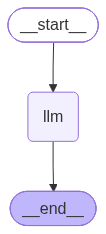

In [45]:
# Visualize your graph
graph

Let's have some fun with your first graph! 🚀

Run the code below to begin talking to it in real-time. Feel free to try different inputs by changing the message content.

Note: If this cell hangs, click the stop button next to the cell.

In [46]:
from course_helper_functions import pretty_print_messages

for chunk in graph.stream(
    {"messages": [{"role": "user", "content": "Tell me about Apple Inc."}]}
):
    pretty_print_messages(chunk)


Update from node llm:


================================== Ai Message ==================================

Apple Inc. is a multinational technology company based in Cupertino, California, known for designing, manufacturing, and selling consumer electronics, software, and online services. Founded by Steve Jobs, Steve Wozniak, and Ronald Wayne on April 1, 1976, Apple started as a personal computer manufacturer. Its first product, the Apple I, was hand-built by Wozniak and sold in a kit form.

Over the years, Apple has expanded and diversified its product lineup significantly. Some of its most notable products include:

1. **Mac Computers**: A line of personal computers that include the MacBook Air, MacBook Pro, iMac, and Mac Mini, known for their design, build quality, and the macOS operating system.

2. **iPhone**: Launched in 2007, the iPhone revolutionized the smartphone industry with its touch interface and ecosystem of apps. It is one of Apple’s most significant products and a major 

### 💡 What did you learn here?

You represented a call to an LLM as a graph, where the LLM, the workflow start, and the workflow end were represented by **nodes** and connected by **edges**.

As you add more components to your graph, including tools and other agents, you'll see how this graph structure allows for greater control and improved reliability in your agentic system.